# LPF 2026 | Apertura vs. Clausura

La comparación abarca los 16 partidos de zonas de cada club en cada torneo.
Los cambios se calculan como **Clausura menos Apertura**. Un cambio positivo
en goles en contra significa que el equipo recibió más goles en el Clausura.

[Fuentes y trazabilidad](../docs/fuentes.md)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from lpf_analytics.resultados import comparar_torneos_2026

actual = Path.cwd()
raiz = next(
    carpeta
    for carpeta in (actual, *actual.parents)
    if (carpeta / "pyproject.toml").is_file()
)
partidos = pd.read_csv(
    raiz / "data/raw/LPF_2026_partidos.csv", encoding="utf-8-sig"
)
comparacion = comparar_torneos_2026(partidos)

columnas = [
    "Equipo", "PTS_Apertura", "PTS_Clausura",
    "Cambio_PTS", "Cambio_GF", "Cambio_GC",
]
comparacion[columnas]

,Equipo,PTS_Apertura,PTS_Clausura,Cambio_PTS,Cambio_GF,Cambio_GC
0,Instituto,21,34,13,9,-2
1,Defensa y Justicia,19,28,9,3,-6
2,Newell's Old Boys,15,23,8,1,-14
3,Rosario Central,28,34,6,6,-4
4,Barracas Central,21,26,5,2,-2
5,Gimnasia (La Plata),26,31,5,6,1
6,Atlético Tucumán,14,18,4,1,-3
7,Estudiantes (Río Cuarto),5,9,4,5,-1
8,Platense,16,20,4,8,5
9,Aldosivi,8,11,3,10,7


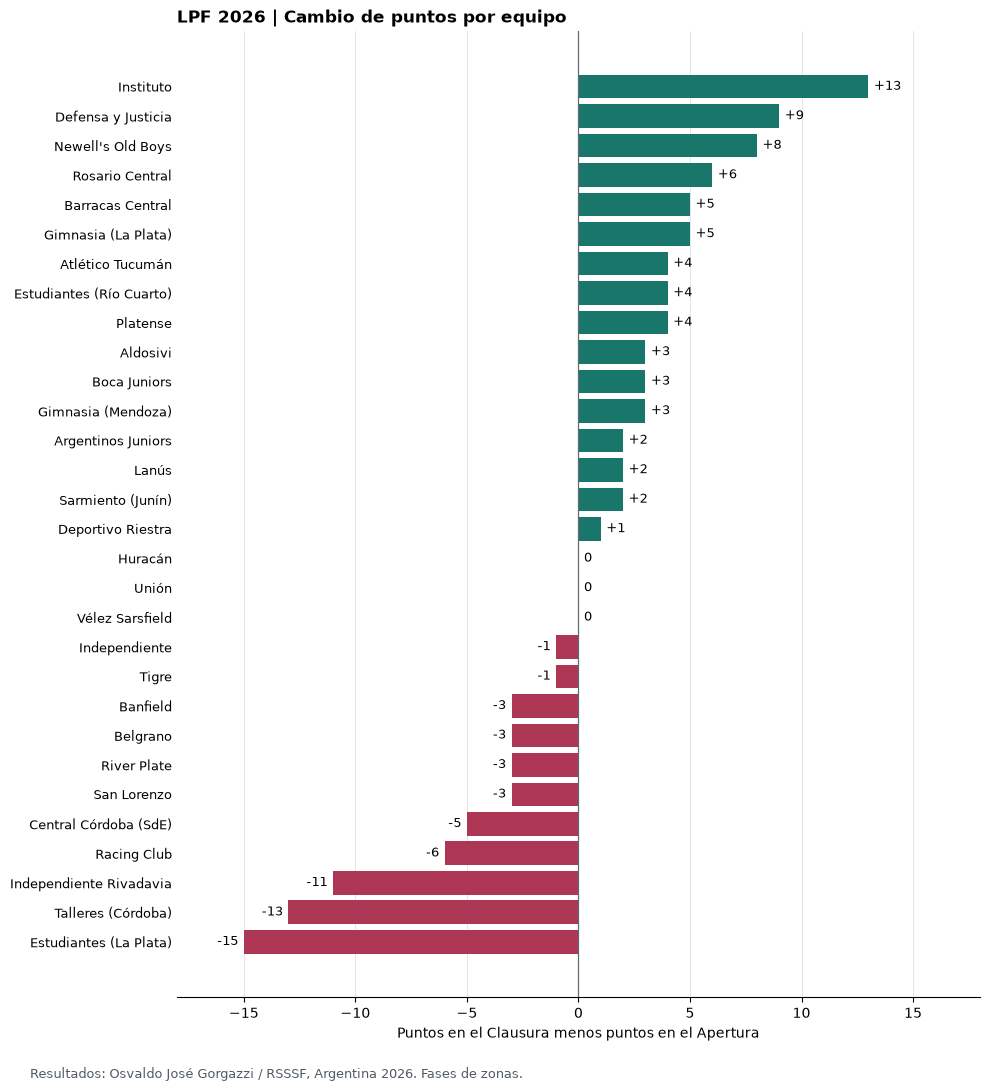

In [2]:
cambios = comparacion["Cambio_PTS"]
colores = cambios.map(lambda valor: "#18776a" if valor > 0 else "#ad3655")

fig, ax = plt.subplots(figsize=(10, 11))
barras = ax.barh(comparacion["Equipo"], cambios, color=colores)
ax.bar_label(
    barras,
    labels=[f"{valor:+d}" if valor else "0" for valor in cambios],
    padding=4,
    fontsize=9,
)
ax.invert_yaxis()
limite = cambios.abs().max() + 3
ax.set_xlim(-limite, limite)
ax.axvline(0, color="#606974", linewidth=0.9)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e1e6ec", linewidth=0.7)
ax.set_title("LPF 2026 | Cambio de puntos por equipo", loc="left", weight="bold")
ax.set_xlabel("Puntos en el Clausura menos puntos en el Apertura")
ax.tick_params(axis="y", length=0, labelsize=9)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)

fig.text(
    0.035, 0.015,
    "Resultados: Osvaldo José Gorgazzi / RSSSF, Argentina 2026. Fases de zonas.",
    fontsize=9, color="#515b68",
)
fig.tight_layout(rect=(0, 0.035, 1, 1))
fig.savefig(raiz / "reports/apertura_vs_clausura_2026.png", dpi=180)
plt.show()

## Cambios que se destacan

Instituto registró el mayor aumento, de 21 a 34 puntos. Estudiantes de La
Plata tuvo la mayor caída, de 31 a 16, y recibió 15 goles más. Newell's
redujo sus goles en contra en 14 y sumó 8 puntos más.

Boca pasó de 30 a 33 puntos. El [notebook de Boca](01_boca_ciclos_2026.ipynb)
desglosa ese cambio entre partidos de local y de visitante.